# DRIVE MOUNTING & DATASET EXTRACTION

In [ ]:
import os
import zipfile
from tqdm import tqdm
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Verify project folder and ZIP file path
drive_folder = "/content/drive/MyDrive/Plant_Disease_Project"
zip_path = os.path.join(drive_folder, "PLANT DISEASE PROJECT .zip")
print("Dataset ZIP exists:", os.path.exists(zip_path))

# Extract dataset to /content/tomato_dataset
extract_path = "/content/tomato_dataset"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    tomato_files = [
        f for f in z.namelist()
        if len(f.split("/")) >= 5
        and f.split("/")[2] in ["train", "valid"]
        and f.split("/")[3].startswith("Tomato___")
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print("Total tomato images to extract:", len(tomato_files))

    for file in tqdm(tomato_files, desc="Extracting Dataset"):
        parts = file.split("/")
        split = parts[2]
        class_name = parts[3]
        filename = parts[-1]

        destination = os.path.join(extract_path, split, class_name, filename)
        os.makedirs(os.path.dirname(destination), exist_ok=True)

        with z.open(file) as source, open(destination, "wb") as target:
            target.write(source.read())

print("Extraction completed successfully!")

Mounted at /content/drive
Mounted at /content/drive
Dataset ZIP exists: True
Dataset ZIP exists: True
Total tomato images to extract: 45860
Total tomato images to extract: 45860


Extracting Dataset: 100%|██████████| 45860/45860 [00:34<00:00, 1335.77it/s]

Extraction completed successfully!


Extraction completed successfully!


# DATA LOADING, NORMALIZATION & PREFETCHING

In [ ]:
TRAIN_DIR = os.path.join(extract_path, "train")
VALID_DIR = os.path.join(extract_path, "valid")

# Using (224, 224) as standard for CNN & Transfer Learning (MobileNetV2)
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load training data
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

Found 18345 files belonging to 10 classes.
Found 18345 files belonging to 10 classes.


In [ ]:
# Load validation data
val_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print(f"\nDetected {NUM_CLASSES} Target Plant Disease Classes:")
for idx, name in enumerate(class_names):
    print(f"  {idx}: {name}")

Found 4585 files belonging to 10 classes.

Detected 10 Target Plant Disease Classes:
  0: Tomato___Bacterial_spot
  1: Tomato___Early_blight
  2: Tomato___Late_blight
  3: Tomato___Leaf_Mold
  4: Tomato___Septoria_leaf_spot
  5: Tomato___Spider_mites Two-spotted_spider_mite
  6: Tomato___Target_Spot
  7: Tomato___Tomato_Yellow_Leaf_Curl_Virus
  8: Tomato___Tomato_mosaic_virus
  9: Tomato___healthy


In [ ]:
# Normalization layer (scales pixel values from [0, 255] to [0.0, 1.0])
normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

# Optimize performance with prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

# BUILD CNN FROM SCRATCH

In [ ]:
scratch_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Convolutional Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(),

    # Convolutional Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(),

    # Classification Head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="Tomato_Scratch_CNN")

# Display architecture summary
scratch_model.summary()

# Compile the model
scratch_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Model: "Tomato_Scratch_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

# TRAIN & EVALUATE SCRATCH CNN

In [ ]:
# Train the scratch model
EPOCHS = 10
history_scratch = scratch_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

# Evaluate on validation dataset
scratch_loss, scratch_accuracy = scratch_model.evaluate(val_ds)
print(f"\nScratch CNN - Validation Accuracy: {scratch_accuracy * 100:.2f}%")

# Plot training vs validation history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_scratch.history["accuracy"], label="Training Accuracy")
plt.plot(history_scratch.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Scratch CNN: Training vs Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_scratch.history["loss"], label="Training Loss")
plt.plot(history_scratch.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Scratch CNN: Training vs Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Save the trained scratch model
scratch_model.save("tomato_cnn_from_scratch.keras")
print("Scratch CNN model saved successfully.")

Epoch 1/10
574/574 ━━━━━━━━━━━━━━━━━━━━ 2223s 4s/step - accuracy: 0.4114 - loss: 1.5922 - val_accuracy: 0.5810 - val_loss: 1.1579
Epoch 2/10
399/574 ━━━━━━━━━━━━━━━━━━━━ 10:04 3s/step - accuracy: 0.5663 - loss: 1.2012

# MODEL EVALUATION: CLASSIFICATION REPORT & CONFUSION MATRIX

Generating predictions on validation data...
144/144 ━━━━━━━━━━━━━━━━━━━━ 16s 81ms/step

Classification Report:
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot     0.9000    0.9106    0.9053       425
                        Tomato___Early_blight     0.8806    0.8604    0.8704       480
                         Tomato___Late_blight     0.8493    0.8402    0.8447       463
                           Tomato___Leaf_Mold     0.8488    0.9915    0.9146       470
                  Tomato___Septoria_leaf_spot     0.9638    0.7936    0.8704       436
Tomato___Spider_mites Two-spotted_spider_mite     0.8687    0.9126    0.8901       435
                         Tomato___Target_Spot     0.9071    0.8118    0.8568       457
       Tomato___Tomato_Yellow_Leaf_Curl_Virus     0.9575    0.9204    0.9386       490
                 Tomato___Tomato_mosaic_virus     0.9500    0.9754    0.9626       448
                 

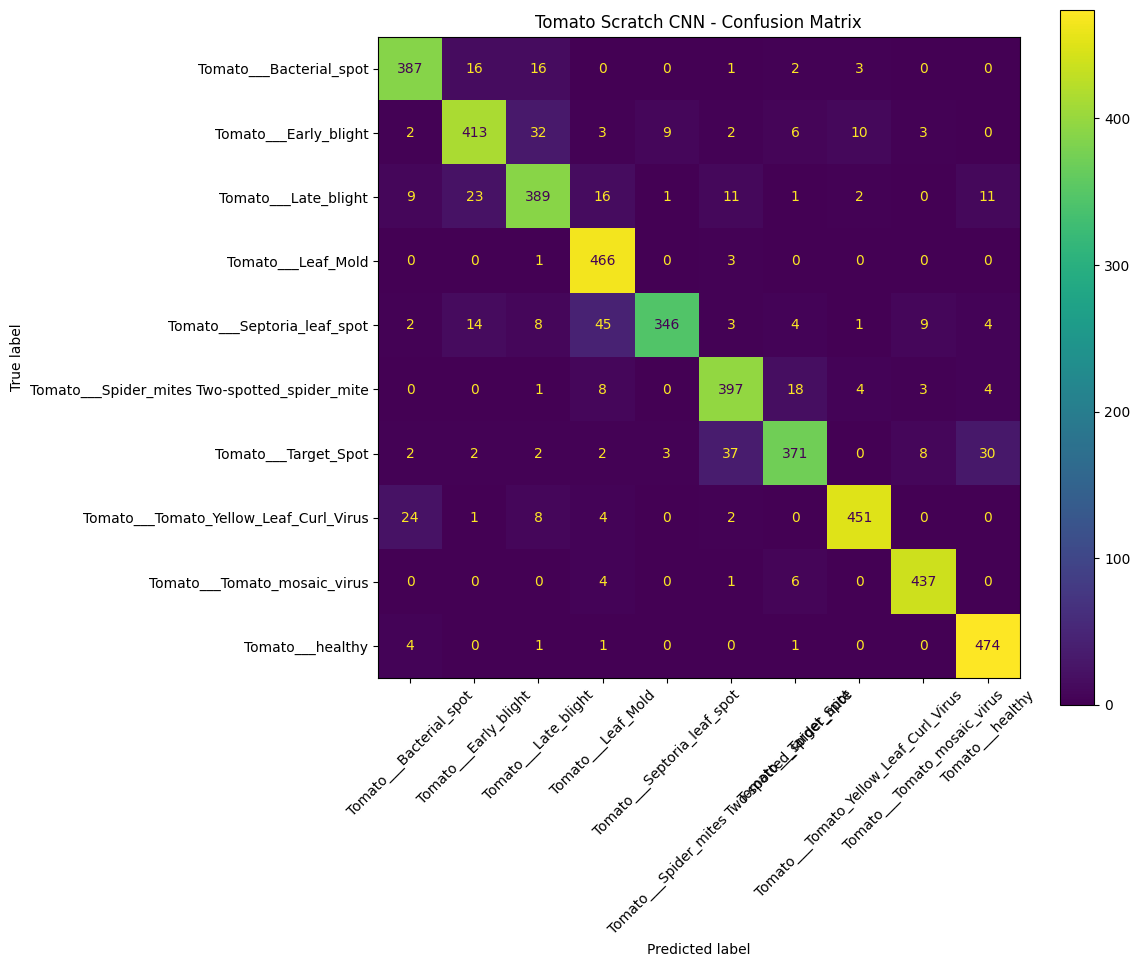

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load the saved scratch model (or your preferred model)
eval_model = load_model("tomato_cnn_from_scratch.keras")

# Generate probabilities on validation dataset
print("Generating predictions on validation data...")
probabilities = eval_model.predict(val_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

# Extract true labels from val_ds
y_true = np.concatenate([y for x, y in val_ds], axis=0)

# Print classification report
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Plot confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, values_format="d", xticks_rotation=45)
plt.title("Tomato Scratch CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

# TRANSFER LEARNING WITH MOBILENETV2

In [ ]:
# Load the pretrained MobileNetV2 base model (excluding top classification head)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the base model layers for feature extraction
base_model.trainable = False

# Build the transfer learning model architecture
inputs = layers.Input(shape=(224, 224, 3))

# MobileNetV2 preprocessing input layer (scales pixels to [-1, 1])
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

# Extract features using frozen base model
x = base_model(x, training=False)

# Global average pooling and classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

transfer_model = models.Model(inputs, outputs, name="Tomato_MobileNetV2_Transfer")

# Display architecture summary
transfer_model.summary()

# Compile the transfer model
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "Tomato_MobileNetV2_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# TRAIN & EVALUATE TRANSFER MODEL

In [ ]:
EPOCHS = 5
history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

# Evaluate transfer learning performance
transfer_loss, transfer_accuracy = transfer_model.evaluate(val_ds)
print(f"\nTransfer Learning - Validation Accuracy: {transfer_accuracy * 100:.2f}%")

# Save the transfer model
transfer_model.save("tomato_mobilenetv2_transfer.keras")
print("Transfer learning model saved successfully.")

Epoch 1/5
574/574 ━━━━━━━━━━━━━━━━━━━━ 71s 81ms/step - accuracy: 0.1193 - loss: 2.3727 - val_accuracy: 0.1555 - val_loss: 2.2130
Epoch 2/5
574/574 ━━━━━━━━━━━━━━━━━━━━ 26s 46ms/step - accuracy: 0.1636 - loss: 2.2383 - val_accuracy: 0.2222 - val_loss: 2.1632
Epoch 3/5
574/574 ━━━━━━━━━━━━━━━━━━━━ 26s 46ms/step - accuracy: 0.1803 - loss: 2.1917 - val_accuracy: 0.2475 - val_loss: 2.1455
Epoch 4/5
574/574 ━━━━━━━━━━━━━━━━━━━━ 26s 45ms/step - accuracy: 0.2021 - loss: 2.1551 - val_accuracy: 0.2412 - val_loss: 2.1208
Epoch 5/5
574/574 ━━━━━━━━━━━━━━━━━━━━ 25s 44ms/step - accuracy: 0.2085 - loss: 2.1370 - val_accuracy: 0.2648 - val_loss: 2.0964
144/144 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.2648 - loss: 2.0964

Transfer Learning - Validation Accuracy: 26.48%
Transfer learning model saved successfully.


# FINE-TUNING MOBILENETV2

In [ ]:
# Unfreeze the base model, then freeze all but the last 30 layers
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a much smaller learning rate for delicate fine-tuning
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train the fine-tuned model
EPOCHS = 5
history_fine = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

# Evaluate the fine-tuned model
fine_loss, fine_accuracy = transfer_model.evaluate(val_ds)
print(f"\nFine-Tuned Model - Validation Accuracy: {fine_accuracy * 100:.2f}%")

# Save the final fine-tuned model
transfer_model.save("tomato_mobilenetv2_finetuned.keras")
print("Fine-tuned MobileNetV2 model saved successfully.")

Epoch 1/5
574/574 ━━━━━━━━━━━━━━━━━━━━ 74s 96ms/step - accuracy: 0.3184 - loss: 3.0654 - val_accuracy: 0.1511 - val_loss: 5.0280
Epoch 2/5
574/574 ━━━━━━━━━━━━━━━━━━━━ 29s 50ms/step - accuracy: 0.4922 - loss: 1.4418 - val_accuracy: 0.1498 - val_loss: 9.6795
Epoch 3/5
574/574 ━━━━━━━━━━━━━━━━━━━━ 41s 51ms/step - accuracy: 0.5465 - loss: 1.2980 - val_accuracy: 0.1128 - val_loss: 11.8860
Epoch 4/5
574/574 ━━━━━━━━━━━━━━━━━━━━ 41s 51ms/step - accuracy: 0.5873 - loss: 1.1918 - val_accuracy: 0.1060 - val_loss: 12.0417
Epoch 5/5
574/574 ━━━━━━━━━━━━━━━━━━━━ 28s 49ms/step - accuracy: 0.6128 - loss: 1.1262 - val_accuracy: 0.1049 - val_loss: 11.2379
144/144 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.1049 - loss: 11.2379

Fine-Tuned Model - Validation Accuracy: 10.49%
Fine-tuned MobileNetV2 model saved successfully.
